# Introducing Pandas

Pandas is a Python library that makes handling tabular data easier. It's one of three libraries you'll encounter repeatedly in the field of data science:

## Pandas
Introduces "Data Frames" and "Series" that allow you to slice and dice rows and columns of information.

## NumPy
Usually you'll encounter "NumPy arrays", which are multi-dimensional array objects. It is easy to create a Pandas DataFrame from a NumPy array, and Pandas DataFrames can be cast as NumPy arrays. 

## Scikit_Learn
The machine learning library we'll use throughout this course is scikit_learn, or sklearn, and it generally takes NumPy arrays as its input.

So, a typical thing to do is to load, clean, and manipulate your input data using Pandas. Then convert your Pandas DataFrame into a NumPy array as it's being passed into some Scikit_Learn function. That conversion can often happen automatically.

Let's start by loading some comma-separated value data using Pandas into a DataFrame:


In [1]:
%matplotlib inline
import numpy as np
import pandas as pd

df = pd.read_csv("PastHires.csv")
df.head()

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,Y,4,BS,N,N,Y
1,0,N,0,BS,Y,Y,Y
2,7,N,6,BS,N,N,N
3,2,Y,1,MS,Y,N,Y
4,20,N,2,PhD,Y,N,N


head can take an integer as an argument :

In [2]:
df.head(10)

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
0,10,Y,4,BS,N,N,Y
1,0,N,0,BS,Y,Y,Y
2,7,N,6,BS,N,N,N
3,2,Y,1,MS,Y,N,Y
4,20,N,2,PhD,Y,N,N
5,0,N,0,PhD,Y,Y,Y
6,5,Y,2,MS,N,Y,Y
7,3,N,1,BS,N,Y,Y
8,15,Y,5,BS,N,N,Y
9,0,N,0,BS,N,N,N


You can also view the data with tail():

In [3]:
df.tail(4)

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
9,0,N,0,BS,N,N,N
10,1,N,1,PhD,Y,N,N
11,4,Y,1,BS,N,Y,Y
12,0,N,0,PhD,Y,N,Y


We often talk about the "shape" of your DataFrame. This is just its dimensions. This particular CSV file has 13 rows with 7 columns per row:

In [4]:
df.shape

(13, 7)

The total size of the data frame is the rows * columns:

In [5]:
df.size

91

The len() function gives you the number of rows in a DataFrame:

In [6]:
len(df)

13

If your DataFrame has named columns (in our case, extracted automatically from the first row of a .csv file,) you can get an array of them back:

In [7]:
df.columns

Index(['Years Experience', 'Employed?', 'Previous employers',
       'Level of Education', 'Top-tier school', 'Interned', 'Hired'],
      dtype='str')

Extracting a single column from your DataFrame looks like this - this gives you back a "Series" in Pandas:

In [8]:
df['Hired']

0     Y
1     Y
2     N
3     Y
4     N
5     Y
6     Y
7     Y
8     Y
9     N
10    N
11    Y
12    Y
Name: Hired, dtype: str

You can also extract a given range of rows from a named column, like so:

In [9]:
df['Hired'][:5]

0    Y
1    Y
2    N
3    Y
4    N
Name: Hired, dtype: str

Or even extract a single value from a specified column / row combination:

In [10]:
df['Hired'][5]

'Y'

To extract more than one column, you pass in an array of column names instead of a single one:

In [11]:
df[['Years Experience', 'Hired']]

,Years Experience,Hired
0,10,Y
1,0,Y
2,7,N
3,2,Y
4,20,N
5,0,Y
6,5,Y
7,3,Y
8,15,Y
9,0,N


You can also extract specific ranges of rows from more than one column, in the way you'd expect:

In [12]:
df[['Years Experience', 'Hired']][:5]

,Years Experience,Hired
0,10,Y
1,0,Y
2,7,N
3,2,Y
4,20,N


Sorting your DataFrame by a specific column looks like this:

In [13]:
df.sort_values(['Years Experience'])

,Years Experience,Employed?,Previous employers,Level of Education,Top-tier school,Interned,Hired
1,0,N,0,BS,Y,Y,Y
5,0,N,0,PhD,Y,Y,Y
12,0,N,0,PhD,Y,N,Y
9,0,N,0,BS,N,N,N
10,1,N,1,PhD,Y,N,N
3,2,Y,1,MS,Y,N,Y
7,3,N,1,BS,N,Y,Y
11,4,Y,1,BS,N,Y,Y
6,5,Y,2,MS,N,Y,Y
2,7,N,6,BS,N,N,N


You can break down the number of unique values in a given column into a Series using value_counts() - this is a good way to understand the distribution of your data:

In [14]:
degree_counts = df['Level of Education'].value_counts()
degree_counts

Level of Education
BS     7
PhD    4
MS     2
Name: count, dtype: int64

Pandas even makes it easy to plot a Series or DataFrame - just call plot():

<Axes: xlabel='Level of Education'>

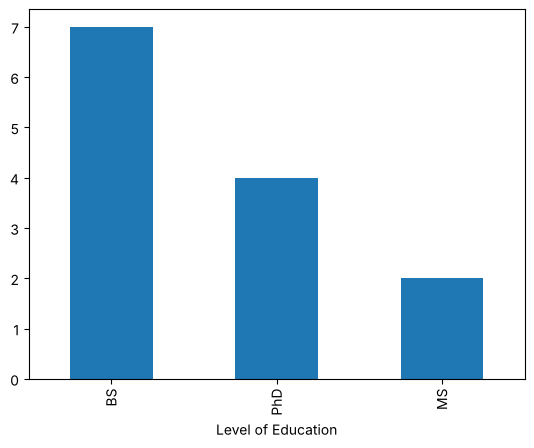

In [15]:
degree_counts.plot(kind='bar')

## Exercise

Try extracting rows 5-10 of our DataFrame, preserving only the "Previous Employers" and "Hired" columns. Assign that to a new DataFrame, and create a histogram plotting the distribution of the previous employers in this subset of the data.

In [16]:
import matplotlib.pyplot as plt

# lignes 5 à 10 (11 exclu) et seulement les 2 colonnes demandées
sub_df = df[['Previous employers', 'Hired']][5:11]
sub_df

,Previous employers,Hired
5,0,Y
6,2,Y
7,1,Y
8,5,Y
9,0,N
10,1,N


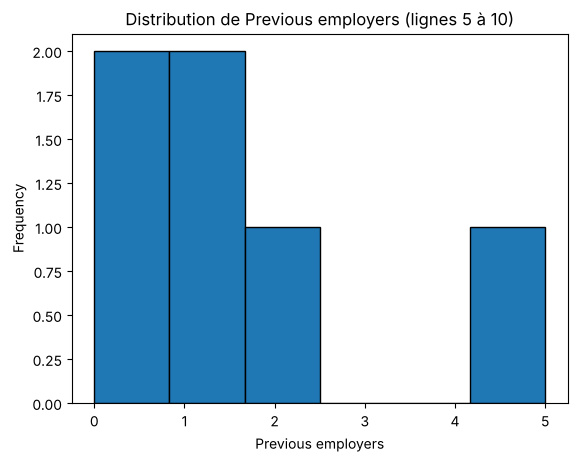

In [17]:
# histogramme de la distribution de Previous employers
sub_df['Previous employers'].plot(kind='hist', bins=6, edgecolor='black')
plt.xlabel('Previous employers')
plt.title('Distribution de Previous employers (lignes 5 à 10)')
plt.show()

Remarque : le sous-ensemble ne contient que 6 lignes, donc l'histogramme est assez pauvre. On voit quand même que la plupart des candidats de cet extrait ont 0, 1 ou 2 employeurs précédents, et qu'un seul en a 5.